# 15. Load Text

This tutorial demonstrates two ways to load and preprocess text.

* First, you will use Keras utilities and preprocessing layers. These include `tf.keras.utils.text_dataset_from_directory` to turn data into a `tf.data.Dataset` and `tf.keras.layers.TextVectorization` for data standardization, tokenization and vectorization. If you are new to TensorFlow, you should start with these.
* Then, you will use lower-level utilities like `tf.data.TextLineDataset` to load text files, `tf.lookup` for custom in-model lookup tables, and TensorFlow Text APIs, such as `text.UnicodeScriptTokenizer` and `text.case_fold_utf8`, to preprocess the data for finer-grain control.

In [1]:
# pip install "tensorflow-text==2.13.*"

In [2]:
import collections
import pathlib

import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers
from tensorflow.keras import losses
from tensorflow.keras import utils
from tensorflow.keras.layers import TextVectorization

import tensorflow_datasets as tfds
import tensorflow_text as tf_text

ModuleNotFoundError: No module named 'tensorflow_text'

### Example 1: Predict the tag for a Stack Overflow question

As a first example, you will download a dataset of programming questions from Stack Overflow. Each question ("How do I sort a dictionary by value?") is labeled with exactly one tag (`Python`, `CSharp`, `JavaScript`, or `Java`). Your task is to develop a model that predicts the tag for a question. This is an example of multi-class classification - an important and widely applicable kind of machine learning problem.

To implement this task, you'll start with the simplest tools:

* `keras.utils.text_dataset_from_directory`: for loading text-file examples.
* `keras.layers.TextVectorization`: for converting strings to token indices.

**Download and explore the dataset**

Begin by downloading the Stack Overflow dataset using `tf.keras.utils.get_file`, and exploring the directory structure:

In [6]:
data_url = "https://storage.googleapis.com/download.tensorflow.org/data/stack_overflow_16k.tar.gz"

dataset_dir = utils.get_file(origin=data_url, untar=True, cache_dir='stack_overflow', cache_subdir='')

dataset_dir = pathlib.Path(dataset_dir).parent

6053168/6053168 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [10]:
dataset_dir = pathlib.Path("C:\\Users\\yigit\\AppData\\Local\\Temp\\.keras\\stack_overflow_16k.tar.gz")

In [11]:
list(dataset_dir.iterdir())

[WindowsPath('C:/Users/yigit/AppData/Local/Temp/.keras/stack_overflow_16k.tar.gz/README.md'),
 WindowsPath('C:/Users/yigit/AppData/Local/Temp/.keras/stack_overflow_16k.tar.gz/test'),
 WindowsPath('C:/Users/yigit/AppData/Local/Temp/.keras/stack_overflow_16k.tar.gz/train')]

In [12]:
train_dir = dataset_dir/'train'
list(train_dir.iterdir())

[WindowsPath('C:/Users/yigit/AppData/Local/Temp/.keras/stack_overflow_16k.tar.gz/train/csharp'),
 WindowsPath('C:/Users/yigit/AppData/Local/Temp/.keras/stack_overflow_16k.tar.gz/train/java'),
 WindowsPath('C:/Users/yigit/AppData/Local/Temp/.keras/stack_overflow_16k.tar.gz/train/javascript'),
 WindowsPath('C:/Users/yigit/AppData/Local/Temp/.keras/stack_overflow_16k.tar.gz/train/python')]

The `train/csharp`, `train/java`, `train/python` and `train/javascript` directories contain many text files, each of which is a Stack Overflow question.

Print an example file and inspect the data:

In [13]:
sample_file = train_dir/'python/1755.txt'

with open(sample_file) as f:
    print(f.read())

why does this blank program print true x=true.def stupid():.    x=false.stupid().print x



**Load the dataset**

Next, you will load the data off-disk and prepare it into a format suitable for training. To do so, you will use the `tf.keras.utils.text_dataset_from_directory` utility to create a labeled `tf.data.Dataset`. If you're new to `tf.data`, it's a powerful collection of tools for building input pipelines. (Learn more in the tf.data: Build Tensorflow input pipelines guide).

The `tf.keras.utils.text_dataset_from_directory` API expects a directory structure as follows:

```
train/
...csharp/
......1.txt
......2.txt
...java/
......1.txt
......2.txt
...javascript/
......1.txt
......2.txt
...python/
......1.txt
......2.txt
```

When running a machine learning experiment, it is a bes practice to divide your dataset into three splits: training, validation, and test.

The Stack Overflow dataset has already been divided into training and test sets, but it lacks a validation set.

Create a validation set using an 80:20 split of the training data by using `tf.keras.utils.text_dataset_from_directory` with `validation_split` set to `0.2` (i.e. 20%):

In [14]:
batch_size = 32
seed = 42

raw_train_ds = utils.text_dataset_from_directory(
    train_dir, batch_size=batch_size, validation_split=0.2, subset='training', seed=seed)

Found 8000 files belonging to 4 classes.
Using 6400 files for training.


As the previous cell output suggests, there are 8,000 examples in the training folder, of which you will use 80% (or 6,400) for training. You will learn in a moment that you can train a model by passing a `tf.data.Dataset` directly to `Model.fit`.

First, iterate over the dataset and print out a few examples, to get a feel for the data.

**Note:** To increase the difficulty of the classification problem, the dataset author replaced occurrences of the words Python, CSharp, JavaScript, or Java in the programming question with the word _blank_.

In [15]:
for text_batch, label_batch in raw_train_ds.take(1):
    for i in range(10):
        print("Question: ", text_batch.numpy()[i])
        print("Label: ", label_batch.numpy()[i])

Question:  b'"my tester is going to the wrong constructor i am new to programming so if i ask a question that can be easily fixed, please forgive me. my program has a tester class with a main. when i send that to my regularpolygon class, it sends it to the wrong constructor. i have two constructors. 1 without perameters..public regularpolygon().    {.       mynumsides = 5;.       mysidelength = 30;.    }//end default constructor...and my second, with perameters. ..public regularpolygon(int numsides, double sidelength).    {.        mynumsides = numsides;.        mysidelength = sidelength;.    }// end constructor...in my tester class i have these two lines:..regularpolygon shape = new regularpolygon(numsides, sidelength);.        shape.menu();...numsides and sidelength were declared and initialized earlier in the testing class...so what i want to happen, is the tester class sends numsides and sidelength to the second constructor and use it in that class. but it only uses the default con

The labels are `0`, `1`, `2`, or `3`. To check which of these correspond to which string label, you can inspect the `class_names` property on the dataset:

In [16]:
for i, label in enumerate(raw_train_ds.class_names):
    print("Label", i, "corresponds to", label)

Label 0 corresponds to csharp
Label 1 corresponds to java
Label 2 corresponds to javascript
Label 3 corresponds to python


Next, you will create a validation and a test set using `tf.keras.utils.text_dataset_from_directory`. You will use the remaining 1,600 reviews from the training set for validation.

**Note:** When using the `validation_split` and `subset` arguments of `tf.keras.utils.text_dataset_from_directory` make sure to either specify a random seed or pass `shuffle=False`, so that the validation and training splits have no overlap.

In [17]:
# Create a validation set
raw_val_ds = utils.text_dataset_from_directory(
    train_dir, batch_size=batch_size, validation_split=0.2, subset='validation', seed=seed)

Found 8000 files belonging to 4 classes.
Using 1600 files for validation.


In [18]:
test_dir = dataset_dir/'test'

# Create a test set
raw_test_ds = utils.text_dataset_from_directory(
    test_dir, batch_size=batch_size)

Found 8000 files belonging to 4 classes.


**Configure the datasets for performance**

These are two important methods you should use when loading data to make sure that I/O does not become blocking.

* `Dataset.cache` keeps data in memory after it's loaded off-disk. This will ensure the dataset does not become a bottleneck while training your model. If your dataset is too large to fit into memory, you can also use this method to create a performant on-disk cache, which is more efficient to read than many small files.
* `Dataset.prefetch` overlaps data preprocessing and model execution while training.

You can learn more about both methods, as well as how to cache data to disk in the _Prefetching_ section of the Better performance with the tf.data API guide.

In [19]:
raw_train_ds = raw_train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
raw_val_ds = raw_val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
raw_test_ds = raw_test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

This first example will keep things simple by integrating the text processing into the model. But you may be able to increase performance by moving the text preprocessing into the dataset pipeline, this is demonstrated in Example 2.

**Prepare the dataset for training**

Next, you will standardize, tokenize, and vectorize the data using the `tf.keras.layers.TextVectorization` layer.

* _Standardization_ refers to preprocessing the text, typically to remove punctuation or HTML elements to simplify the dataset.
* _Tokenization_ refers to splitting strings into tokens (for example, splitting a sentence into individual words by splitting on whitespace).
* _Vectorization_ refers to converting tokens into numbers so they can be fed into a neural network.

All of these teasks can be accomplished with this layer. (You can learn more about each of these in the `tf.keras.layers.TextVectorization` API docs.)

Note that:

* The default standardization converts text to lowercase and removes punctuation (`standardize='lower_and_strip_punctuation'`).
* The default tokenizer splits on whitespace (`split='whitespace'`).
* The default vectorization mode is `'int'` (`output_mode='int'`). This outputs integer indices (one per token). This mode can be used to build models that take word order into account. You can also use other modes -like `'binary'` - to build bag-of-words models.

You will build two models to learn more about standardization, tokenization, and vectorization with `TextVectorization`.

* First, you will use the `'binary'` vectorization mode to build a bag-of-words model.
* Then, you will use the `'int'` mode with a 1D ConvNet.

In [20]:
VOCAB_SIZE = 10000

binary_vectorize_layer = TextVectorization(max_tokens=VOCAB_SIZE, output_mode='binary')

For the `'int'` mode, in addition to maximum vocabulary size, you need to set an explicit maximum sequence length (`MAX_SEQUENCE_LENGTH`), which will cause the layer to pad or truncate to exactly `output_sequence_length` values:

In [21]:
MAX_SEQUENCE_LENGTH = 250

int_vectorize_layer = TextVectorization(max_tokens=VOCAB_SIZE, output_mode='int', output_sequence_length=MAX_SEQUENCE_LENGTH)

Next, call `TextVectorization.adapt` to fit the state of the preprocessing layer to the dataset. This will cause the model to build an index of strings to integers.

**Note:** It's important to only use your training data when calling `TextVectorization.adapt` as using the test set would leak information.

In [22]:
# Make a text-only dataset (without labels), then call 'TextVectorization.adapt'.
train_text = raw_train_ds.map(lambda text, labels: text)
binary_vectorize_layer.adapt(train_text)
int_vectorize_layer.adapt(train_text)

Print the result of using these layers to preprocess data:

In [23]:
# Retrieve a batch (of 32 reviews and labels) from the dataset
text_batch, label_batch = next(iter(raw_train_ds))
first_question, first_label = text_batch[0], label_batch[0]
print("Question:", first_question)
print("Label:", first_label)

Question: tf.Tensor(b'"blank8 why is my solution faster than the neat solution? (hackerrank chocolate feast) edit: simplified my solution..edit: removed opinion based secondary question...background: atarted learning blank a week or two ago using hackerranks problems as exercises and stackoverflow search + google as my teacher, i\'ve had some limited experience learning other languages...i did the exercise my own ""noobish learner way"" which i can\'t help but feel is a ""botched job"" when i see ""neat &amp; short"" solutions...however, when submitting both solutions one after another a couple of times i found the ""neat"" solution was quite a bit slower. ..i vaguely remember something about % operations being costly, is mine faster because of no % operations or is there more to it than just that?..exercise: https://www.hackerrank.com/challenges/chocolate-feast..neat solution from discussion:..import blank.io.*;.import blank.util.*;..public class solution {.    static int cc; .    pub

The binary vectorization layer returns a multi-hot vector, with a 1 in the location for each token that was in the input string.

(0.0, 1000.0)

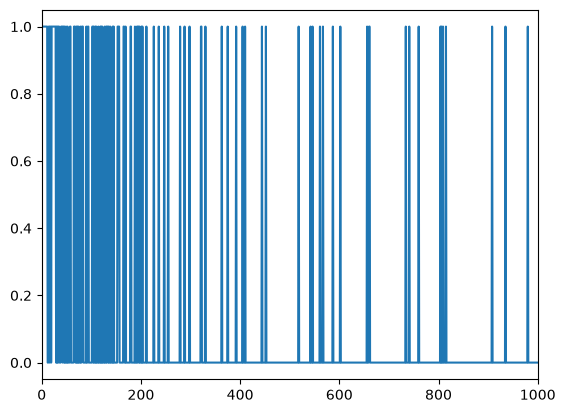

In [25]:
# print("'binary' vectorized question:", list(binary_vectorize_layer(first_question).numpy()))

plt.plot(binary_vectorize_layer(first_question).numpy())
plt.xlim(0, 1000)

In [27]:
print("'int' vectorized question:", int_vectorize_layer(first_question).numpy())

'int' vectorized question: [   1  111    6   23  299 1787  198    2 3623  299 7826    1    1  805
 2568   23    1 1218 3892  364 4145    1    1  661   16    5  981   45
  121 1881   47    1  742   36 9987    8 1982  322  662   36   23 2362
  195  543   83 2693 2609  661  144    1  411    2 1371   23  657    1
 6520   84   66    3  166  104   26 1182    6    5    1 1639   44    3
  189 3623  519 1135    1   44 5468  280 1272   71  156  157    5 1759
    9  331    3  227    2 3623  299  115  810    5  547 3833    3    1
 2371  146  202 1195  289    1    6 2179 1787  193    9  136 1195   45
    6   67  181    4   11  198  106    1    1  299   31    1 2216 1924
   29  299   53   28 2081   22   53   42  170  154  256    7   15  453
   28    1  237 2698    1  134 2698  131 2698  323 2698    1    1    1
    1    1    1   23    1 2216 1924   29  299   22   53   42  170  154
  256 1360   15  453   28  237    1  237   68    9  196  807   28 7167
    1  237    1 1364    1  562    1 4406  735 1820

As shown above, `TextVectorization`'s `'binary'` mode returns an array denoting which tokens exist at least once in the input, while the `'int'` mode replaces each token by an integer, thus preserving their order.

You can lookup the token (string) that each integer corresponds to by calling `TextVectorization.get_vocabulary` on the layer:

In [28]:
print("1289 ---> ", int_vectorize_layer.get_vocabulary()[1289])
print("313 ---> ", int_vectorize_layer.get_vocabulary()[313])
print("Vocabulary size: {}".format(len(int_vectorize_layer.get_vocabulary())))

1289 --->  roman
313 --->  source
Vocabulary size: 10000


**Train the model**

It's time to create your neural network.

For the `'binary'` vectorized data, define a simple bag-of-words linear model, then configure and train it:

In [32]:
binary_model = tf.keras.Sequential([
    binary_vectorize_layer,
    layers.Dense(4)])

binary_model.compile(
    loss=losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer='adam',
    metrics=['accuracy'])

# tf.keras.utils.plot_model(binary_model, show_shapes=True)
# ValueError: This model has not yet been built. Build the model first by calling `build()` or by calling the model on a batch of data.

In [33]:
bin_history = binary_model.fit(raw_train_ds, validation_data=raw_val_ds, epochs=10)

Epoch 1/10


C:\Users\yigit\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.6456 - loss: 1.1134 - val_accuracy: 0.7731 - val_loss: 0.9131
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8153 - loss: 0.7772 - val_accuracy: 0.8012 - val_loss: 0.7504
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.8606 - loss: 0.6264 - val_accuracy: 0.8106 - val_loss: 0.6650
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8886 - loss: 0.5331 - val_accuracy: 0.8244 - val_loss: 0.6117
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9041 - loss: 0.4673 - val_accuracy: 0.8338 - val_loss: 0.5750
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9194 - loss: 0.4171 - val_accuracy: 0.8350 - val_loss: 0.5484
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9289 - loss: 0.3769 - val_accuracy: 0.8400 - val_loss: 0.5283
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9353 - loss: 0.3437 - val_accuracy: 0.840

Next, you will use the `'int'` vectorized layer to build a 1D ConvNet:

In [34]:
def create_model(vocab_size, num_labels, vectorizer=None):
    my_layers = []
    if vectorizer is not None:
        my_layers = [vectorizer]

    my_layers.extend([
        layers.Embedding(vocab_size, 64, mask_zero=True),
        layers.Dropout(0.5),
        layers.Conv1D(64, 5, padding="valid", activation="relu", strides=2),
        layers.GlobalMaxPooling1D(),
        layers.Dense(num_labels)
    ])

    model = tf.keras.Sequential(my_layers)
    return model

In [37]:
# 'vocab_size' is 'VOCAB_SIZE + 1' since '0' is used additionally for padding.
int_model = create_model(vocab_size=VOCAB_SIZE + 1, num_labels=4, vectorizer=int_vectorize_layer)

# tf.keras.utils.plot_model(int_model, show_shapes=True)
# ValueError: This model has not yet been built. Build the model first by calling `build()` or by calling the model on a batch of data.

In [38]:
int_model.compile(
    loss=losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer='adam',
    metrics=['accuracy'])

In [40]:
int_history = int_model.fit(raw_train_ds, validation_data=raw_val_ds, epochs=10)

Epoch 1/10


C:\Users\yigit\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\layer.py:1039: UserWarning: Layer 'conv1d_2' (of type Conv1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 48ms/step - accuracy: 0.4133 - loss: 1.2603 - val_accuracy: 0.6144 - val_loss: 0.9166
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - accuracy: 0.6747 - loss: 0.7799 - val_accuracy: 0.7362 - val_loss: 0.6537
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - accuracy: 0.7908 - loss: 0.5729 - val_accuracy: 0.7931 - val_loss: 0.5467
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - accuracy: 0.8659 - loss: 0.4162 - val_accuracy: 0.8169 - val_loss: 0.4966
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - accuracy: 0.9019 - loss: 0.3051 - val_accuracy: 0.8163 - val_loss: 0.4854
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - accuracy: 0.9402 - loss: 0.2164 - val_accuracy: 0.8219 - val_loss: 0.4986
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.9625 - loss: 0.1487 - val_accuracy: 0.8150 - val_loss: 0.5160
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.9722 - loss: 0.1077 - val_accuracy: 0

Text(0, 0.5, 'CE/token')

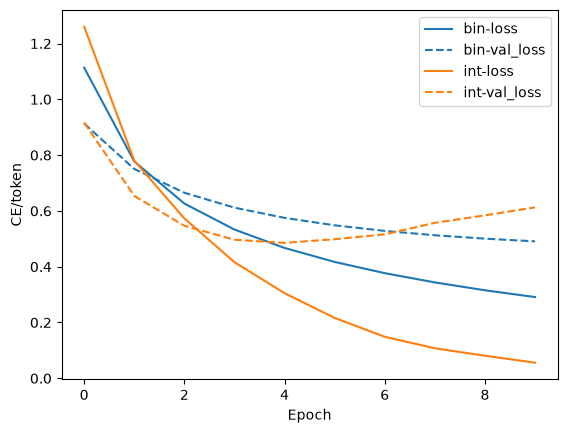

In [43]:
loss = plt.plot(bin_history.epoch, bin_history.history['loss'], label='bin-loss')
plt.plot(bin_history.epoch, bin_history.history['val_loss'], '--', color=loss[0].get_color(), label='bin-val_loss')

loss = plt.plot(int_history.epoch, int_history.history['loss'], label='int-loss')
plt.plot(int_history.epoch, int_history.history['val_loss'], '--', color=loss[0].get_color(), label='int-val_loss')

plt.legend()
plt.xlabel('Epoch')
plt.ylabel('CE/token')

You are nearly readt to train your model.

As a final preprocessing step, you will apply the `TextVectorization` layers you created earlier to the training, validation, and test sets:

In [44]:
binary_train_ds = raw_train_ds.map(lambda x, y: (binary_vectorize_layer(x), y))
binary_val_ds = raw_val_ds.map(lambda x, y: (binary_vectorize_layer(x), y))
binary_test_ds = raw_test_ds.map(lambda x, y: (binary_vectorize_layer(x), y))

int_train_ds = raw_train_ds.map(lambda x, y: (int_vectorize_layer(x), y))
int_val_ds = raw_val_ds.map(lambda x, y: (int_vectorize_layer(x), y))
int_test_ds = raw_test_ds.map(lambda x, y: (int_vectorize_layer(x), y))

**Export the model**

In [45]:
binary_model.export('bin.tf')

INFO:tensorflow:Assets written to: bin.tf\assets


INFO:tensorflow:Assets written to: bin.tf\assets


Saved artifact at 'bin.tf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None,), dtype=tf.string, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  2295079155280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2295079154128: TensorSpec(shape=(), dtype=tf.int64, name=None)
  2295079144336: TensorSpec(shape=(), dtype=tf.string, name=None)
  2295079149520: TensorSpec(shape=(), dtype=tf.int64, name=None)
  2295079446544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2295079443856: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [46]:
loaded = tf.saved_model.load('bin.tf')

In [49]:
binary_model.predict(['How do you sort a list?'])

ValueError: Unrecognized data type: x=['How do you sort a list?'] (of type <class 'list'>)

In [50]:
loaded.serve(tf.constant(['How do you sort a list?'])).numpy()

array([[-0.09258482,  0.03625127, -0.6218063 ,  0.37181258]],
      dtype=float32)

Including the text preprocessing logic inside your model enables you to export a model for production that simplifies deployment, and reduces the potential for train/test skew.

There is a performance difference to keep in mind when choosing where to apply `tf.keras.layers.TextVectorization`. Using it outside of your model enables you to do asynchronous CPU processing and buffering of your data when training on GPU. So, if you're training your model on the GPU, you probably want to go with this option to get the best performance while developing your model, then switch to including the `TextVectorization` layer inside your model when you're ready to prepare for deployment.

Visit the Save and load models tutorial to learn more about saving models.

### Example 2: Predict the author of Iliad translations

The following provides an example of using `tf.data.TextLineDataset` to load examples from text files, and TensorFlow Text to preprocess the data. You will use three different English translations of the same work, Homer's Iliad, and train a model to identify the translator given a single line of text.

To implement this task you'll use some lower level tools.

* You'll use `tf.data.TextLineDataset` to load text-lines from files.
* You'll implement your own version of `keras.layers.TextVectorization` using:
  * `text.UnicodeScriptTokenizer` - to convert strings to tokens.
  * `tf.lookup.StaticVocabularyTable` - to convert tokens to integer ids.
* You'll maximize performance by plaing the text processing in the dataset pipeline, so it can run in parallel with the model training.

**Download and explore the dataset**

The texts of the three translations are by:

* William Cowper: text
* Edward, Earl of Derby: text
* Samuel Butler: text

The text files in this tutorial have undergone some typical preprocessing tasks like removing document header and footer, line numbers and chapter titles.

Download these lightly munged files locally:

In [51]:
DIRECTORY_URL = 'https://storage.googleapis.com/download.tensorflow.org/data/illiad/'
FILE_NAMES = ['cowper.txt', 'derby.txt', 'butler.txt']

for name in FILE_NAMES:
    text_dir = utils.get_file(name, origin=DIRECTORY_URL + name)

parent_dir = pathlib.Path(text_dir).parent
list(parent_dir.iterdir())

815980/815980 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
809730/809730 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
807992/807992 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step


[WindowsPath('C:/Users/yigit/.keras/datasets/194px-New_East_River_Bridge_from_Brooklyn_det.4a09796u.jpg'),
 WindowsPath('C:/Users/yigit/.keras/datasets/320px-Felis_catus-cat_on_snow.jpg'),
 WindowsPath('C:/Users/yigit/.keras/datasets/butler.txt'),
 WindowsPath('C:/Users/yigit/.keras/datasets/cowper.txt'),
 WindowsPath('C:/Users/yigit/.keras/datasets/derby.txt'),
 WindowsPath('C:/Users/yigit/.keras/datasets/fashion-mnist'),
 WindowsPath('C:/Users/yigit/.keras/datasets/flower_photos.tgz'),
 WindowsPath('C:/Users/yigit/.keras/datasets/flower_photos.tgz_archive'),
 WindowsPath('C:/Users/yigit/.keras/datasets/heart.csv'),
 WindowsPath('C:/Users/yigit/.keras/datasets/HIGGS.csv.gz'),
 WindowsPath('C:/Users/yigit/.keras/datasets/mnist.npz')]

**Load the dataset**

Previously, with `tf.keras.utils.text_dataset_from_directory` all contents of a file were treated as a single example. Here, you will use `tf.data.TextLineDataset`, which is designed to create a `tf.data.Dataset` from a text file where each example is a line of text from the original file. `TextLineDataset` is useful for text data that is primarily line-based (for example, poetry or error logs).

Iterate through these files, loading each one into its own dataset. Each example needs to be individually labeled, so use `Dataset.map` to apply a labeler function to each one. This will iterate over every example in the dataset, returning `(example, label)` pairs.

In [52]:
def labeler(example, index):
    return example, tf.cast(index, tf.int64)

In [53]:
labeled_data_sets = []

for i, file_name in enumerate(FILE_NAMES):
    lines_dataset = tf.data.TextLineDataset(str(parent_dir/file_name))
    labeled_dataset = lines_dataset.map(lambda ex: labeler(ex, i))
    labeled_data_sets.append(labeled_dataset)

In [54]:
parent_dir

WindowsPath('C:/Users/yigit/.keras/datasets')

Next, you'll combine these labeled datasets into a single dataset using `Dataset.concatenate` and shuffle it with `Dataset.shuffle`:

In [55]:
BUFFER_SIZE = 50000
BATCH_SIZE = 64
VALIDATION_SIZE = 5000

In [56]:
all_labeled_data = labeled_data_sets[0]
for labeled_dataset in labeled_data_sets[1:]:
    all_labeled_data = all_labeled_data.concatenate(labeled_dataset)

all_labeled_data = all_labeled_data.shuffle(BUFFER_SIZE, reshuffle_each_iteration=False)

Print out a few examples as before. The dataset hasn't been batched yet, hence each entry in `all_labeled_data` corresponds to one data point:

In [57]:
for text, label in all_labeled_data.take(10):
    print("Sentence:", text.numpy())
    print("Label:", label.numpy())

Sentence: b'But though their horses have the speed of thine,'
Label: 1
Sentence: b'Of darkness, but the third is yet entire.'
Label: 0
Sentence: b'Of all the battle where the Caucons stood.'
Label: 0
Sentence: b'how the son of Atreus treated me with contumely as though I were some'
Label: 2
Sentence: b'Thrice forty warriors, had arrived at Troy.'
Label: 0
Sentence: b'Furling, they stowed them in the bark below.'
Label: 0
Sentence: b"Girt with the arms of Peleus' godlike son,"
Label: 1
Sentence: b'undertakes the hazardous enterprise, and makes choice of Ulysses for'
Label: 1
Sentence: b"Whom he hath slain, Podes, E\xc3\xabtion's son?"
Label: 0
Sentence: b'His two attendants, of his followers all,'
Label: 1


**Prepare the dataset for training**

Instead of using `tf.keras.layers.TextVectorization` to preprocess the text dataset, you will now use the lower-level TensorFlow Text APIs to standardize and tokenize the data, build a vocabulary and use `tf.lookup.StaticVocabularyTable` to map tokens to integers to feed to the model. (Learn more about TensorFlow Text).

Define a function to convert the text to lower-case and tokenize it:

* TensorFlow Text provides various tokenizers. In this example, you will use the `text.UnicodeScriptTokenizer` to tokenize the dataset.
* You will use `Dataset.map` to apply the tokenization to the dataset.

In [58]:
class MyTokenizer(tf.keras.layers.Layer):
    def __init__(self):
        super().__init__()
        self.tokenizer = tf_text.UnicodeScriptTokenizer()

    def call(self, text):
        lower_case = tf_text.case_fold_utf8(text)
        result = self.tokenizer.tokenize(lower_case)
        # If you pass a batch of strings, it will return a RaggedTensor.
        if isinstance(result, tf.RaggedTensor):
            # Convert to dense 0-padded.
            result = result.to_tensor()
        return result

In [59]:
tokenizer = MyTokenizer()

NameError: name 'tf_text' is not defined

In [60]:
tokenized_ds = all_labeled_data.map(lambda text, label: (tokenizer(text), label))
tokenized_ds

NameError: in user code:

    File "C:\Users\yigit\AppData\Local\Temp\ipykernel_38864\1817331830.py", line 1, in None  *
        lambda text, label: (tokenizer(text), label)

    NameError: name 'tokenizer' is not defined


`<_MapDataset element_spec=(TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>`

You can iterate over the dataset and print out a few tokenized examples:

In [61]:
for tokens, label in tokenized_ds.take(1):
    break

print(tokens)
print()
print(label)

NameError: name 'tokenized_ds' is not defined

```
tf.Tensor(
[b'and' b'proto' b',' b'pherusa' b'and' b'dynamene' b',' b'dexamene' b','
 b'amphinome' b'and' b'callianeira' b','], shape=(13,), dtype=string)

tf.Tensor(2, shape=(), dtype=int64)
```

Next, you will build a vocabulary by sorting tokens by frequency and keeping the top `VOCAB_SIZE` tokens:

In [62]:
tokenized_ds = tokenized_ds.cache().prefetch(tf.data.AUTOTUNE)

vocab_count = collections.Counter()
for toks, labels in tokenized_ds.ragged_batch(1000):
    toks = tf.reshape(toks, [-1])
    for tok in toks.numpy():
        vocab_count[tok] += 1

voccab = [tok for tok, count in vocab_count.most_common(VOCAB_SIZE)]

print("First five vocab entries:", vocab[:5])
print()

NameError: name 'tokenized_ds' is not defined

`First five vocab entries: [b',', b'the', b'and', b"'", b'of']`

To convert tokens into integers, use the `vocab` set to create a `tf.lookup.StaticVocabularyTable`. You will map tokens to integers with `0` reserved for padding, and `n+1` reserved to denote an out-of-vocabulary (OOV) token.

In [63]:
class MyVocabTable(tf.keras.layers.Layer):
    def __init__(self, vocab):
        super().__init__()
        self.keys = [''] + vocab
        self.values = range(len(self.keys))

        self.init = tf.lookup.KeyValueTensorInitializer(self.keys, self.values, key_dtype=tf.string, value_dtype=tf.int64)

        num_oov_buckets = 1

        self.table = tf.lookup.StaticVocabularyTable(self.init, num_oov_buckets)

    def call(self, x):
        result = self.table.lookup(x)
        return result

Try it on a dummy vocabulary:

In [64]:
vocab_table = MyVocabTable(['a', 'b', 'c'])
vocab_table(tf.constant([''] + list('abcdefghi')))

<tf.Tensor: shape=(10,), dtype=int64, numpy=array([0, 1, 2, 3, 4, 4, 4, 4, 4, 4])>

Create one for the real vocabulary:

In [65]:
vocab_table = MyVocabTable(vocab)

NameError: name 'vocab' is not defined

Finally, define a lyer to standardize, tokenize and vectorize the dataset using the tokenizer and lookup table:

In [66]:
preprocess_text = tf.keras.Sequential([tokenizer, vocab_table])

NameError: name 'tokenizer' is not defined

You can try this on a single example to print the output:

In [67]:
example_text, example_label = next(iter(all_labeled_data))
print("Sentence: ", example_text.numpy())
vectorized_text = preprocess_text(example_text)
print("Vectorized sentence: ", vectorized_text.numpy())

Sentence:  b'But though their horses have the speed of thine,'


NameError: name 'preprocess_text' is not defined

```
Sentence:  b'and Proto, Pherusa and Dynamene, Dexamene, Amphinome and Callianeira.'
Vectorized sentence:  [   3 7805    1 7806    3 7807    1 7808    1 7809    3 9790    1]
```

Now create a dataset pipeline that will process the text on the fly using `Dataset.map`:

In [68]:
all_encoded_data = all_labeled_data.map(lambda text, labels: (preprocess_text(text), labels))

for ids, label in all_encoded_data.take(1):
    break

print("Ids:", ids.numpy())
print("Label:", label.numpy())

NameError: in user code:

    File "C:\Users\yigit\AppData\Local\Temp\ipykernel_38864\1505517304.py", line 1, in None  *
        lambda text, labels: (preprocess_text(text), labels)

    NameError: name 'preprocess_text' is not defined


```
Ids:  [   3 7805    1 7806    3 7807    1 7808    1 7809    3 9790    1]
Label: 2
```

**Split the dataset into training and test sets**

The Keras `TextVectorization` layer also batches and pads the vectorized data. Padding is required because the examples inside of a batch need to be the same size and shape, but the examples in these datasets are not all the same size - each line of text has a different number of words.

`tf.data.Dataset` supports splitting and padded-batching datasets:

In [69]:
train_data = all_encoded_data.skip(VALIDATION_SIZE).shuffle(BUFFER_SIZE).padded_batch(BATCH_SIZE)
validation_data = all_encoded_data.take(VALIDATION_SIZE).padded_batch(BATCH_SIZE)

NameError: name 'all_encoded_data' is not defined

Now, `validation_data` and `train_data` are not collections of `(example, label)` pairs, but collections of batches. Each batch is a pair of _(many examples, many labels)_ represented as arrays.

To illustrate this:

In [70]:
sample_text, sample_labels = next(iter(validation_data))
print("Text batch shape: ", sample_text.shape)
print("Label batch shape: ", sample_labels.shape)
print("First text example: ", sample_text[0])
print("First label example: ", sample_labels[0])

NameError: name 'validation_data' is not defined

```
Text batch shape:  (64, 18)
Label batch shape:  (64,)
First text example:  tf.Tensor(
[   3 7805    1 7806    3 7807    1 7808    1 7809    3 9790    1    0
    0    0    0    0], shape=(18,), dtype=int64)
First label example. tf.Tensor(2, shape=(), dtype=int64)
```

Configure the datasets for better performance as before:

In [71]:
train_data = train_data.prefetch(tf.data.AUTOTUNE)
validation_data = validation_data.prefetch(tf.data.AUTOTUNE)

NameError: name 'train_data' is not defined

**Train the model**

You can train a model on this dataset as before:

Since this text vectorization adds `0` for padding and `n+1` for out-of-vocabulary (OOV) tokens, the vocabulary size has increased by two:

In [72]:
model = create_model(vocab_size=VOCAB_SIZE+2, num_labels=3)

model.compile(
    optimizer='adam',
    loss=losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'])

In [74]:
# tf.keras.utils.plot_model(model, show_shapes=True)
# ValueError: This model has not yet been built. Build the model first by calling `build()` or by calling the model on a batch of data.

In [75]:
history = model.fit(train_data, validation_data=validation_data, epochs=3)

NameError: name 'train_data' is not defined

```
Epoch 1/3
697/697 [========================] - 30s 10ms/step - loss: 0.5868 - accuracy: 0.7339 - val_loss: 0.4017 - val_accuracy: 0.8302
Epoch 2/3
697/697 [========================] - 28s 10ms/step - loss: 0.3642 - accuracy: 0.8489 - val_loss: 0.3574 - val_accuracy: 0.8472
Epoch 3/3
697/697 [========================] - 29s 9ms/step - loss: 0.2910 - accuracy: 0.8808 - val_loss: 0.3527 - val_accuracy: 0.8506
```

In [76]:
metrics = model.evaluate(validation_data, return_dict=True)

print("Loss: ", metrics['loss'])
print("Accuracy: {:2.2%}".format(metrics['accuracy']))

NameError: name 'validation_data' is not defined

```
79/79 [========================] - 3s 29ms/step - loss: 0.3527 - accuracy: 0.8506
Loss:  0.35271939635276794
Accuracy: 85.06%
```

**Export the model**

To make the model capable of taking raw strings as input, pack both the text processor and the model into a `keras.Sequential`:

In [77]:
export_model = tf.keras.Sequential([
    preprocess_text, model
])

NameError: name 'preprocess_text' is not defined

In [78]:
export_model.compile(
    loss=losses.SparseCategoricalCrossentropy(from_logits=False),
    optimizer='adam',
    metrics=['accuracy'])

NameError: name 'export_model' is not defined

This model you can run directly on batches of strings:

In [79]:
# Create a test dataset of raw strings.
test_ds = all_labeled_data.take(VALIDATION_SIZE).batch(BATCH_SIZE)
test_ds = test_ds.cache().prefetch(tf.data.AUTOTUNE)
test_ds

<_PrefetchDataset element_spec=(TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>

In [80]:
loss, accuracy = export_model.evaluate(test_ds)

print("Loss: ", loss)
print("Accuracy: {:2.2%}".format(accuracy))

NameError: name 'export_model' is not defined

```
79/79 [========================] - 5s 9ms/step - loss: 1.0300 - accuracy: 0.8506
Loss: 1.0299931764602661
Accuracy: 85.06%
```

Use `saved_model.save` to export it.

In [82]:
tf.saved_model.save(export_model, 'export.tf')

NameError: name 'export_model' is not defined

```
INFO:tensorflow:Assets written to: export.tf/assets
INFO:tensorflow:Assets written to: export.tf/assets
```

In [83]:
loaded = tf.saved_model.load('export.tf')

OSError: SavedModel file does not exist at: export.tf\{saved_model.pbtxt|saved_model.pb}

In [84]:
export_model(tf.constant(['The field bristles with the long and deadly spears which they bore.'])).numpy()

NameError: name 'export_model' is not defined

`array([[-3.2765586 , -0.37794957 , 3.0517902 ]], dtype=float32)`

In [85]:
loaded(tf.constant(['The field bristled with the long and deadly spears which they bore.'])).numpy()

TypeError: '_UserObject' object is not callable

`array([[-3.2765586 , -0.37794957,  3.0517902 ]], dtype=float32)`

The loss and accuracy for the model on encoded validation set and the exported model on the raw validation set are the same, as expected.

**Run inference on new data**

In [87]:
inputs = [
    "Join'd to th' Ionians with their flowing robes,",   # Label: 1
    "the allies, and his armous flashed about him so that he seemed to all",   # Label: 2
    "And with loud clangor of his arms he fell.",   # Label: 0
]

In [89]:
predicted_scores = export_model.predict(inputs)
predicted_labels = tf.math.argmax(predicted_scores, axis=1)

for input, label in zip(inputs, predicted_labels):
    print("Question: ", input)
    print("Predicted label: ", label.numpy())

NameError: name 'export_model' is not defined

```
1/1 [========================] - 2s 2s/step
Question: Join'd to th' Ionians with their flowing robes,
Predicted label:  1
Question: the allies, and his armour flashed about him so that he seemed to all
Predicted label:  2
Question:  And with loud clangor of his arms he fell.
Predicted label:  0
```

### Download more datasets using TensorFlow Datasets (TFDS)

You can download many more datasets from TensorFlow Datasets.

In this example, you will use the IMDB Large Movie Review dataset to train a model for sentiment classification:

In [90]:
# Training set
train_ds = tfds.load(
    'imdb_reviews',
    split='train[:80%]',
    batch_size=BATCH_SIZE,
    shuffle_files=True,
    as_supervised=True)

In [91]:
# Validation set
val_ds = tfds.load(
    'imdb_reviews',
    split='train[80%:]',
    batch_size=BATCH_SIZE,
    shuffle_files=True,
    as_supervised=True)

Print a few examples:

In [92]:
for review_batch, label_batch in val_ds.take(1):
    for i in range(5):
        print("Review: ", review_batch[i].numpy())
        print("Label: ", label_batch[i].numpy())

Review:  b"Instead, go to the zoo, buy some peanuts and feed 'em to the monkeys. Monkeys are funny. People with amnesia who don't say much, just sit there with vacant eyes are not all that funny.<br /><br />Black comedy? There isn't a black person in it, and there isn't one funny thing in it either.<br /><br />Walmart buys these things up somehow and puts them on their dollar rack. It's labeled Unrated. I think they took out the topless scene. They may have taken out other stuff too, who knows? All we know is that whatever they took out, isn't there any more.<br /><br />The acting seemed OK to me. There's a lot of unfathomables tho. It's supposed to be a city? It's supposed to be a big lake? If it's so hot in the church people are fanning themselves, why are they all wearing coats?"
Label:  0
Review:  b'Well, was Morgan Freeman any more unusual as God than George Burns? This film sure was better than that bore, "Oh, God". I was totally engrossed and LMAO all the way through. Carrey was

You can now preprocess the data and train a model as before.

**Note:** You will use `tf.keras.losses.BinaryCrossentropy` instead of `tf.keras.losses.SparseCategoricalCrossentropy` for your model, since this is a binary classification problem.

**Prepare the dataset for training**

In [93]:
vectorize_layer = TextVectorization(max_tokens=VOCAB_SIZE, output_mode='int', output_sequence_length=MAX_SEQUENCE_LENGTH)

# Make a text-only dataset (without labels), then call 'TextVectorization.adapt'.
train_text = train_ds.map(lambda text, labels: text)
vectorize_layer.adapt(train_text)

In [94]:
def vectorize_text(text, label):
    text = tf.expand_dims(text, -1)
    return vectorize_layer(text), label

In [96]:
train_ds = train_ds.map(vectorize_text)
val_ds = val_ds.map(vectorize_text)

In [97]:
# Configure datasets for performance as before
train_ds = train_ds.cache().prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(tf.data.AUTOTUNE)

**Create, configure and train the model**

In [98]:
model = create_model(vocab_size=VOCAB_SIZE, num_labels=1)
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_4 (Conv1D)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_max_pooling1d_4               │ ?                           │               0 │
│ (GlobalMaxPooling1D)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [99]:
model.compile(
    loss=losses.BinaryCrossentropy(from_logits=True),
    optimizer='adam',
    metrics=['accuracy'])

In [101]:
history = model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3


UnimplementedError: {{function_node __wrapped__MakeIterator_device_/job:localhost/replica:0/task:0/device:CPU:0}} Cast int64 to string is not supported
	 [[{{node text_vectorization_2_1/Cast}}]] [Op:MakeIterator] name: 

```
Epoch 1/3
313/313 [========================] - 5s 12ms/step - loss: 0.5965 - accuracy: 0.6120 - val_loss: 0.4267 - val_accuracy: 0.7970
Epoch 2/3
313/313 [========================] - 3s 10ms/step - loss: 0.3725 - accuracy: 0.8299 - val_loss: 0.3418 - val_accuracy: 0.8454
Epoch 3/3
313/313 [========================] - 3s 10ms/step - loss. 0.2846 - accuracy: 0.8781 - val_loss: 0.3165 - val_accuracy: 0.8584
```

In [102]:
loss, accuracy = model.evaluate(val_ds)

print("Loss: ", loss)
print("Accuracy: {:2.2%}".format(accuracy))

C:\Users\yigit\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\layer.py:1039: UserWarning: Layer 'conv1d_4' (of type Conv1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.4938 - loss: 0.6934
Loss:  0.693443238735199
Accuracy: 49.38%


```
79/79 [========================] - 0s 2ms/step - loss: 0.3165 - accuracy: 0.8584
Loss: 0.2165397047996521
Accuracy: 85.84%
```

**Export the model**

In [103]:
export_model = tf.keras.Sequential([
    vectorize_layer, model,
    layers.Activation('sigmoid')])

export_model.compile(
    loss=losses.SparseCategoricalCrossentropy(from_logits=False),
    optimizer='adam',
    metrics=['accuracy'])

In [104]:
# 0 --> negative review
# 1 --> positive review
inputs = [
    "This is a fantastic movie.",
    "This is a bad movie.",
    "This movie was so bad that it was good.",
    "I will never say yes to watching this movie.",
]

predicted_scores = export_model.predict(inputs)
predicted_labels = [int(round(x[0])) for x in predicted_scores]

for input, label in zip(inputs, predicted_labels):
    print("Question: ", input)
    print("Predicted label: ", label)

ValueError: Unrecognized data type: x=['This is a fantastic movie.', 'This is a bad movie.', 'This movie was so bad that it was good.', 'I will never say yes to watching this movie.'] (of type <class 'list'>)

```
1/1 [========================] - 0s 100ms/step
Question:  This is a fantastic movie.
Predicted label:  1
Question:  This is a bad movie.
Predicted label: 0
Question:  This movie was so bad that it was good.
Predicted label: 0
Question: I will never say yes to watching this movie.
Predicted label: 1
```

### Conclusion

This tutorial demonstrated several ways to load and preprocess text. As a next step, you can explore additional text preprocessing TensorFlow Text tutorials, such as:

* BERT Preprocessing with TF Text
* Tokenizing with TF Text
* Subword tokenizers

You can also find new datasets on TensorFlow Datasets. And, to learn more about `tf.data`, check out the guide on building input pipelines.